In [43]:
import numpy as np
# pandas: for loading and working with tabular data (DataFrames), like a spreadsheet in code
import pandas as pd
# matplotlib: the base plotting library that most other plotting tools build on
import matplotlib.pyplot as plt
# seaborn: makes nicer statistical plots (boxplots, heatmaps, histograms) with less code
import seaborn as sns
import re
# train_test_split: splits our data into a training set and a test set
from sklearn.model_selection import train_test_split
# ColumnTransformer: lets us apply different preprocessing to different columns
# (e.g. scale the numbers, one-hot encode the categories) all in one step
from sklearn.compose import ColumnTransformer
# Pipeline: chains preprocessing steps and a model together, so we can call
# .fit() / .predict() once instead of doing each step by hand every time
from sklearn.pipeline import Pipeline
# StandardScaler: rescales numeric columns to mean 0 / standard deviation 1.
#   This matters a lot for KNN (it measures distance) and helps Logistic Regression too.
# OneHotEncoder: turns text categories (like "Rainy", "Clear") into 0/1 columns,
#   since models can only work with numbers, not raw text
from sklearn.preprocessing import StandardScaler, OneHotEncoder
# SimpleImputer: fills in missing values automatically (e.g. with the median,
# or with whatever value shows up most often in that column)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
# Silence non-critical warnings so the notebook's output stays easy to read
import warnings
warnings.filterwarnings("ignore")

##  Setup and data loading

In [44]:
car_df = pd.read_csv("car details v4 (1).csv")
print("Shape:", car_df.shape)
car_df.head(10)

Shape: (2059, 20)


,Make,Model,Price,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,Seller Type,Engine,Max Power,Max Torque,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
0,Honda,Amaze 1.2 VX i-VTEC,505000,2017,87150,Petrol,Manual,Pune,Grey,First,Corporate,1198 cc,87 bhp @ 6000 rpm,109 Nm @ 4500 rpm,FWD,3990.0,1680.0,1505.0,5.0,35.0
1,Maruti Suzuki,Swift DZire VDI,450000,2014,75000,Diesel,Manual,Ludhiana,White,Second,Individual,1248 cc,74 bhp @ 4000 rpm,190 Nm @ 2000 rpm,FWD,3995.0,1695.0,1555.0,5.0,42.0
2,Hyundai,i10 Magna 1.2 Kappa2,220000,2011,67000,Petrol,Manual,Lucknow,Maroon,First,Individual,1197 cc,79 bhp @ 6000 rpm,112.7619 Nm @ 4000 rpm,FWD,3585.0,1595.0,1550.0,5.0,35.0
3,Toyota,Glanza G,799000,2019,37500,Petrol,Manual,Mangalore,Red,First,Individual,1197 cc,82 bhp @ 6000 rpm,113 Nm @ 4200 rpm,FWD,3995.0,1745.0,1510.0,5.0,37.0
4,Toyota,Innova 2.4 VX 7 STR [2016-2020],1950000,2018,69000,Diesel,Manual,Mumbai,Grey,First,Individual,2393 cc,148 bhp @ 3400 rpm,343 Nm @ 1400 rpm,RWD,4735.0,1830.0,1795.0,7.0,55.0
5,Maruti Suzuki,Ciaz ZXi,675000,2017,73315,Petrol,Manual,Pune,Grey,First,Individual,1373 cc,91 bhp @ 6000 rpm,130 Nm @ 4000 rpm,FWD,4490.0,1730.0,1485.0,5.0,43.0
6,Mercedes-Benz,CLA 200 Petrol Sport,1898999,2015,47000,Petrol,Automatic,Mumbai,White,Second,Individual,1991 cc,181 bhp @ 5500 rpm,300 Nm @ 1200 rpm,FWD,4630.0,1777.0,1432.0,5.0,NaN
7,BMW,X1 xDrive20d M Sport,2650000,2017,75000,Diesel,Automatic,Coimbatore,White,Second,Individual,1995 cc,188 bhp @ 4000 rpm,400 Nm @ 1750 rpm,AWD,4439.0,1821.0,1612.0,5.0,51.0
8,Skoda,Octavia 1.8 TSI Style Plus AT [2017],1390000,2017,56000,Petrol,Automatic,Mumbai,White,First,Individual,1798 cc,177 bhp @ 5100 rpm,250 Nm @ 1250 rpm,FWD,4670.0,1814.0,1476.0,5.0,50.0
9,Nissan,Terrano XL (D),575000,2015,85000,Diesel,Manual,Mumbai,White,First,Individual,1461 cc,84 bhp @ 3750 rpm,200 Nm @ 1900 rpm,FWD,4331.0,1822.0,1671.0,5.0,50.0


## Handling Data 


In [45]:
car_df['Max Power'] = car_df['Max Power'].astype(str).str.extract(r'^(\d+(?:\.\d+)?)')[0].astype(float)
current_year = 2026
car_df['Year'] = current_year - car_df['Year']
print(car_df["Year"].head(10))


0     9
1    12
2    15
3     7
4     8
5     9
6    11
7     9
8     9
9    11
Name: Year, dtype: int64


In [46]:
car_df.dropna(subset=['Max Power'], inplace=True)

# Create the Power Area Product column "Feature engineering"


In [47]:
car_df["Power Area Product"] = car_df["Length"] * car_df["Width"] * car_df["Max Power"]

In [48]:
car_df.head()

,Make,Model,Price,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,...,Engine,Max Power,Max Torque,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity,Power Area Product
0,Honda,Amaze 1.2 VX i-VTEC,505000,9,87150,Petrol,Manual,Pune,Grey,First,...,1198 cc,87.0,109 Nm @ 4500 rpm,FWD,3990.0,1680.0,1505.0,5.0,35.0,5.831784e+08
1,Maruti Suzuki,Swift DZire VDI,450000,12,75000,Diesel,Manual,Ludhiana,White,Second,...,1248 cc,74.0,190 Nm @ 2000 rpm,FWD,3995.0,1695.0,1555.0,5.0,42.0,5.010928e+08
2,Hyundai,i10 Magna 1.2 Kappa2,220000,15,67000,Petrol,Manual,Lucknow,Maroon,First,...,1197 cc,79.0,112.7619 Nm @ 4000 rpm,FWD,3585.0,1595.0,1550.0,5.0,35.0,4.517279e+08
3,Toyota,Glanza G,799000,7,37500,Petrol,Manual,Mangalore,Red,First,...,1197 cc,82.0,113 Nm @ 4200 rpm,FWD,3995.0,1745.0,1510.0,5.0,37.0,5.716446e+08
4,Toyota,Innova 2.4 VX 7 STR [2016-2020],1950000,8,69000,Diesel,Manual,Mumbai,Grey,First,...,2393 cc,148.0,343 Nm @ 1400 rpm,RWD,4735.0,1830.0,1795.0,7.0,55.0,1.282427e+09


## Missing-value handling

In [49]:
car_df.isnull().sum()

Make                   0
Model                  0
Price                  0
Year                   0
Kilometer              0
Fuel Type              0
Transmission           0
Location               0
Color                  0
Owner                  0
Seller Type            0
Engine                 0
Max Power              0
Max Torque             0
Drivetrain            63
Length                 0
Width                  0
Height                 0
Seating Capacity       0
Fuel Tank Capacity    42
Power Area Product     0
dtype: int64

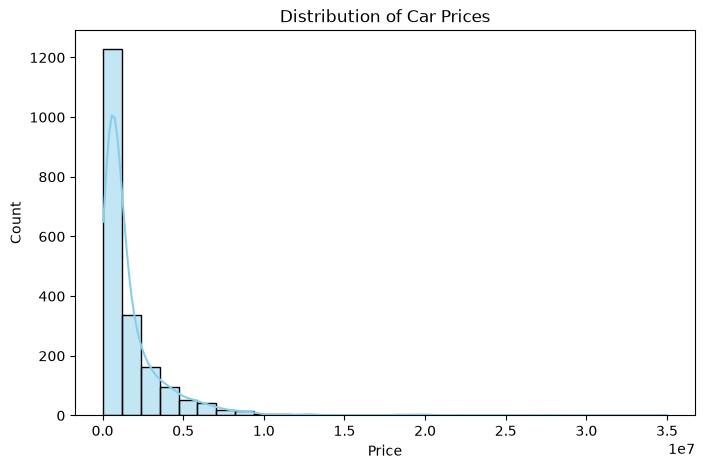

In [50]:
plt.figure(figsize=(8, 5))
sns.histplot(car_df['Price'], kde=True, bins=30, color='skyblue')
plt.title('Distribution of Car Prices')
plt.xlabel('Price')
plt.ylabel('Count')
plt.show()

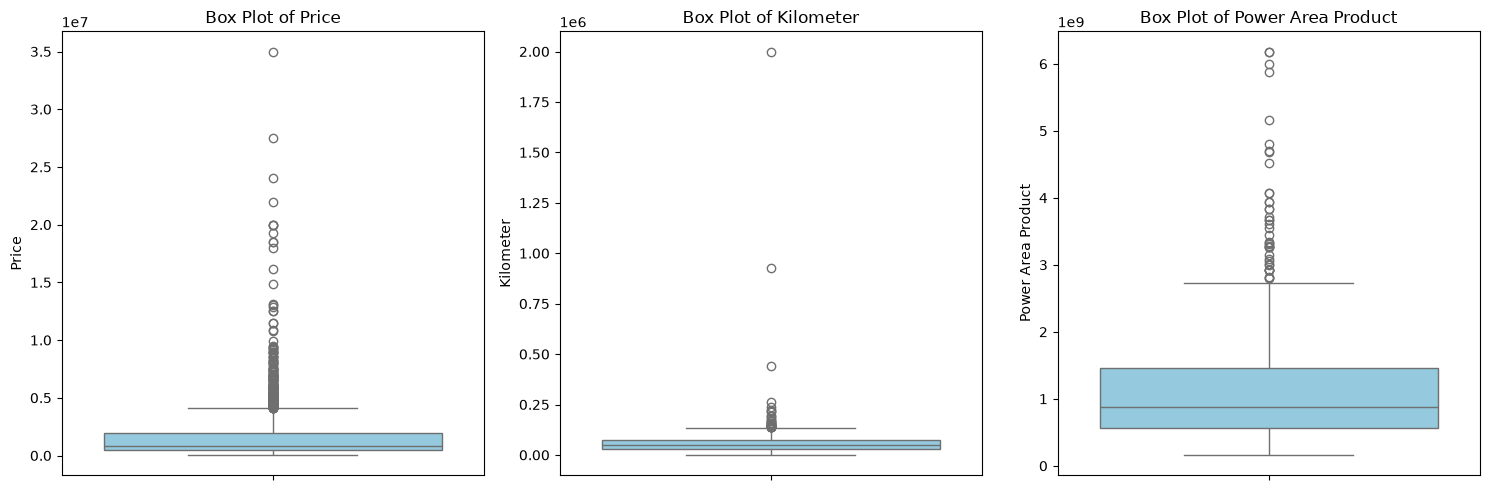

In [51]:
# Plot box plots to visualize outliers before removal
plt.figure(figsize=(15, 5))
columns_to_plot = ['Price', 'Kilometer', 'Power Area Product']

for i, col in enumerate(columns_to_plot, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(y=car_df[col], color='skyblue')
    plt.title(f'Box Plot of {col}')
    plt.ylabel(col)

plt.tight_layout()
plt.show()

# OUTLIER REMOVAL 
# Remove extreme outliers in Price and Kilometer using the Interquartile Range (IQR) method

In [52]:
for col in ['Kilometer', 'Power Area Product']:
    Q1 = car_df[col].quantile(0.25)
    Q3 = car_df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    # Filter out records outside the bounds
    car_df = car_df[(car_df[col] >= lower_bound) & (car_df[col] <= upper_bound)]

print(f"Dataset shape after outlier removal: {car_df.shape}")

Dataset shape after outlier removal: (1905, 21)


In [53]:
car_df.head()

,Make,Model,Price,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,...,Engine,Max Power,Max Torque,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity,Power Area Product
0,Honda,Amaze 1.2 VX i-VTEC,505000,9,87150,Petrol,Manual,Pune,Grey,First,...,1198 cc,87.0,109 Nm @ 4500 rpm,FWD,3990.0,1680.0,1505.0,5.0,35.0,5.831784e+08
1,Maruti Suzuki,Swift DZire VDI,450000,12,75000,Diesel,Manual,Ludhiana,White,Second,...,1248 cc,74.0,190 Nm @ 2000 rpm,FWD,3995.0,1695.0,1555.0,5.0,42.0,5.010928e+08
2,Hyundai,i10 Magna 1.2 Kappa2,220000,15,67000,Petrol,Manual,Lucknow,Maroon,First,...,1197 cc,79.0,112.7619 Nm @ 4000 rpm,FWD,3585.0,1595.0,1550.0,5.0,35.0,4.517279e+08
3,Toyota,Glanza G,799000,7,37500,Petrol,Manual,Mangalore,Red,First,...,1197 cc,82.0,113 Nm @ 4200 rpm,FWD,3995.0,1745.0,1510.0,5.0,37.0,5.716446e+08
4,Toyota,Innova 2.4 VX 7 STR [2016-2020],1950000,8,69000,Diesel,Manual,Mumbai,Grey,First,...,2393 cc,148.0,343 Nm @ 1400 rpm,RWD,4735.0,1830.0,1795.0,7.0,55.0,1.282427e+09


In [54]:
# Apply log transformation to target variable to reduce its high skewness
y = np.log(car_df["Price"])

drop_cols = ["Price", "Width", "Length", "Max Power", "Max Torque", "Engine", "Model"]
x = car_df.drop(columns=list(dict.fromkeys(drop_cols)), errors="ignore")

# Apply log transformation to heavily skewed numerical features
x['Kilometer'] = np.log1p(x['Kilometer'])
x['Power Area Product'] = np.log(x['Power Area Product'])

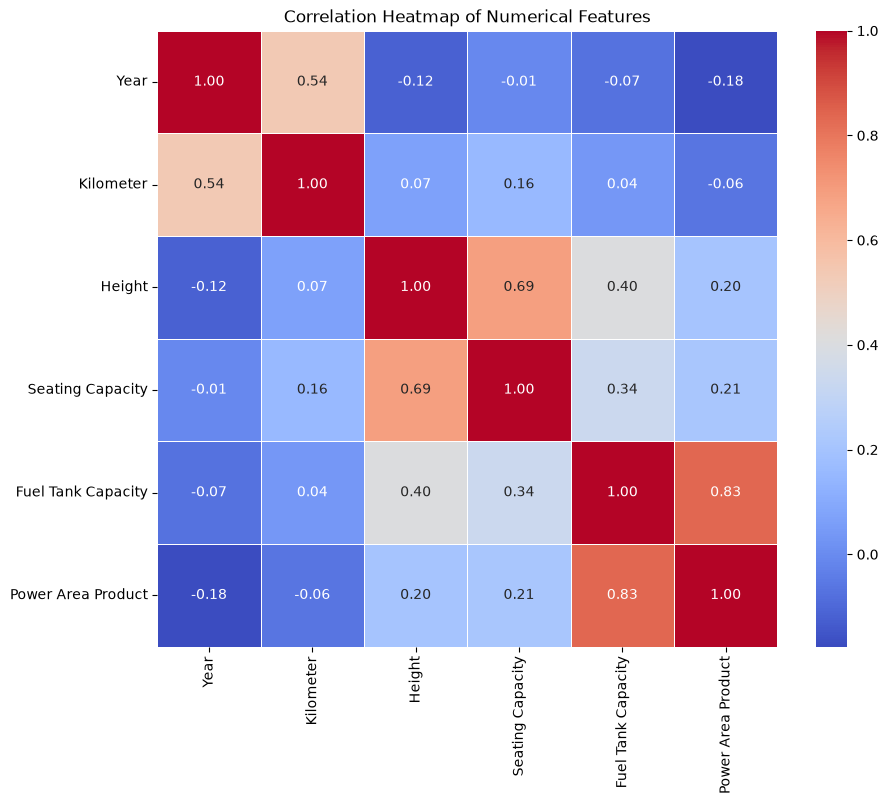

In [56]:
plt.figure(figsize=(10, 8))
sns.heatmap(x.select_dtypes(include=np.number).corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

In [57]:
numeric_features = x.select_dtypes(include=np.number).columns.tolist()
categorical_features = x.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

Numerical features: ['Year', 'Kilometer', 'Height', 'Seating Capacity', 'Fuel Tank Capacity', 'Power Area Product']

Categorical features: ['Make', 'Fuel Type', 'Transmission', 'Location', 'Color', 'Owner', 'Seller Type', 'Drivetrain']


In [58]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [59]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')), # Fills numeric nulls with training median
    ('scaler', StandardScaler())                 # Scales numerical features to mean=0, variance=1
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')), # Fills categorical nulls with training mode
    ('onehot', OneHotEncoder(handle_unknown='ignore')) # Handles categorical text via One-Hot Encoding
])

In [60]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# 6. Create the Full Pipeline (Preprocessing + Model)
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# 7. Train the Pipeline (Fits imputers/encoders on X_train, then fits Linear Regression)
pipeline.fit(X_train, y_train)

# 8. Evaluate on the Test Set
y_pred = pipeline.predict(X_test)
print(f"Pipeline R-squared Score: {r2_score(y_test, y_pred):.4f}")

Pipeline R-squared Score: 0.9493


Adjusted Pipeline R-squared Score: 0.9493


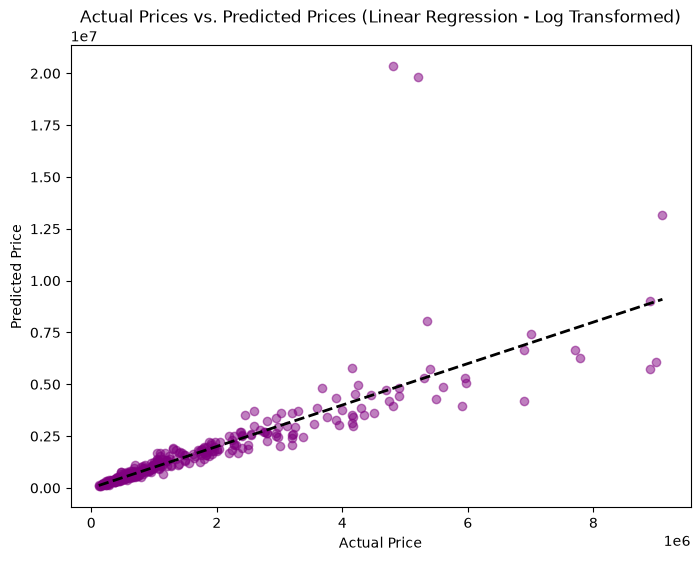

In [61]:
# Convert log-predictions and actual test values back to original price scale for evaluation
y_test_actual = np.expm1(y_test)
y_pred_actual = np.expm1(y_pred)

print(f"Adjusted Pipeline R-squared Score: {r2_score(y_test, y_pred):.4f}")

# Plot actual vs predicted prices on the original scale
plt.figure(figsize=(8, 6))
plt.scatter(y_test_actual, y_pred_actual, alpha=0.5, color='purple')
plt.plot([y_test_actual.min(), y_test_actual.max()], [y_test_actual.min(), y_test_actual.max()], 'k--', lw=2)
plt.title('Actual Prices vs. Predicted Prices (Linear Regression - Log Transformed)')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.show()